In [106]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit, prange
from scipy.linalg import expm
import matplotlib.lines as mlines


# GLOBAL STYLE SETTINGS (run once)

plt.rcParams.update({

    # --- FONT SIZES ---
    "font.size": 24,              # base font size
    "axes.titlesize": 20,         # title
    "axes.labelsize": 36,         # x/y labels
    "xtick.labelsize": 36,
    "ytick.labelsize": 36,
    "legend.fontsize": 16,

    # --- LINES ---
    "lines.linewidth": 5,
    "lines.markersize": 16,

    # --- FIGURE / AXIS ---
    "figure.figsize": (8, 6),
    "figure.dpi": 120,
    "axes.linewidth": 1.5,        # thicker axis spines

    # --- TICKS ---
    "xtick.major.size": 15,
    "xtick.major.width": 3,
    "ytick.major.size": 15,
    "ytick.major.width": 3,

    # --- LEGEND ---
    "legend.frameon": True,
    "legend.framealpha": 0.8,
    "legend.fancybox": True,

    # --- GRID (optional) ---
    #"axes.grid": True,
    #"grid.alpha": 0.3,
})


In [7]:
def compete_four_pops_multinomial(tau, mu, nu, dt, PopSize=10**8, steps=None):


    # 16 types Pop[TR,VR]
    Pop = np.zeros((4,4), dtype=np.int64)

    
    Pop[0,:] = PopSize//4

    # environment favours VR = 0 → 1 → 2 → 3 → 0 → ...
    Hcycle = [
        np.array([0,1,0,0]),
        np.array([0,0,1,0]),
        np.array([0,0,0,1])
    ]
    Hindex = 0
    H = Hcycle[Hindex]

    next_switch = tau/dt

    freqTR=[]
    AvH=[]
    for k in range(steps):

        # ---- Environment switch ----
        if k > next_switch:
            Hindex = (Hindex + 1) % 3
            H = Hcycle[Hindex]
            next_switch += tau/dt

        # ---- SELECTION ----
        # growth factors for each VR
        w = np.exp(H * dt)  # size 4 vector

        # weighted population
        weighted = Pop * w  # broadcasting over VR
        total_fit = weighted.sum()

        # normalized reproduction probability per (TR,VR)
        P_repro = weighted / total_fit

        # sample next generation
        counts = P_repro.reshape(-1)
        new_counts = np.random.multinomial(PopSize, counts)
        Pop = new_counts.reshape(4,4)

        # ---- TR mutation (sequence mutation) ----
        # each TR mutates with rate mu to uniform TR
        for vr in range(4):
            for tr in range(4):
                count = Pop[tr,vr]
                if count == 0: continue

                # number mutating
                m = np.random.binomial(count, mu*dt)
                if m > 0:
                    Pop[tr,vr] -= m
                    # redistribute among TR=0..3
                    redist = np.random.multinomial(m, [1/4]*4)
                    Pop[:,vr] += redist

        # ---- VR switching (genotype change using DGR(TR)) ----
        for tr in range(4):
            for vr in range(4):
                count = Pop[tr,vr]
                if count == 0: continue

                # number switching genotype
                s = np.random.binomial(count, nu*dt)
                if s == 0:
                    continue

                Pop[tr,vr] -= s
                if tr!=0:
                    Pop[tr,tr]+=s
                else:
                    Pop[tr,:]+=np.random.multinomial(s, [1/4]*4)

        # statistics
        freqTR.append(Pop[:,:] / PopSize)
        AvH.append(np.sum(Pop*H/PopSize))
    return np.array(freqTR)[3*int(tau/dt):]


In [8]:
def compute_lambda(dt,nu,tau,Q):
    x=np.arange(int(tau/dt))*dt
    
    def solve_n0_n1(T, nu,Q=4, tol=1e-12):
        """
        Solve the 2x2 linear system for n0(t), n1(t) with arbitrary initial conditions.
        T : numpy array of times (shape (nt,))
        nu, Q : parameters
        n0_init, n1_init : initial values at t=0
        Returns (n0, n1) numpy arrays of same shape as T.
        """
    
        # constants
        Delta = np.sqrt((1.0 - nu)**2 + 4.0 * nu / Q)
        lam_p = (1.0 - nu + Delta) / 2.0
        lam_m = (1.0 - nu - Delta) / 2.0
    
        a11 = 1.0 - nu * (Q - 1.0) / Q
        a12 = nu / Q
    
        # eigenvector ratios v1/v0
        r_p = (lam_p - a11) / a12
        r_m = (lam_m - a11) / a12
    
        denom = (r_p - r_m)
    
        n0_init=r_p/(Q-1)/(1+r_p)
        n1_init=1-n0_init
        # handle generic (non-degenerate) case
        if abs(denom) > tol:
            C_p = (n1_init - r_m * n0_init) / denom
            C_m = (r_p * n0_init - n1_init) / denom
    
            n0 = C_p * np.exp(lam_p * T) + C_m * np.exp(lam_m * T)
            n1 = C_p * r_p * np.exp(lam_p * T) + C_m * r_m * np.exp(lam_m * T)
    
            return n0, n1
    
    sol_0,sol_1=solve_n0_n1(x, nu)
    lamb=sol_0/(sol_0+sol_1)
    return lamb



def compute_fractions_CF(lamb, dt, mu, nu, Q, f0_NM, f0_NT, f0_TT, f0_TM):
    """
    Compute final values of the fractions f_NM, f_NT, f_TT, f_TM
    using the integral formulas with exponentials inside the integral.
    """

    lamb = np.asarray(lamb)
    N = len(lamb)
    t = np.arange(N) * dt
    Lambda = np.cumsum(lamb) * dt

    # ---------------- f_TM ----------------
    I_TM = np.zeros(N)
    for i in range(1, N):
        # exponential factor inside the sum
        I_TM[i] = np.sum(np.exp(nu * (t[:i] - t[i]) + (Lambda[:i] - Lambda[i])) * (1 - lamb[:i])) * dt
    f_TM = f0_TM * np.exp(-nu*t - Lambda) + (mu/Q) * I_TM

    # ---------------- f_NT ----------------
    I_NT = np.zeros(N)
    for i in range(1, N):
        I_NT[i] = np.sum(np.exp((-1+nu) * (t[:i] - t[i]) + (Lambda[:i] - Lambda[i])) * lamb[:i]) * dt
    f_NT = f0_NT * np.exp((1-nu)*t - Lambda) + (mu*(Q-2)/Q) * I_NT

    # ---------------- f_TT ----------------
    I_TT = np.zeros(N)
    for i in range(1, N):
        I_TT[i] = np.sum(np.exp((-t[:i] + t[i]) + (Lambda[:i] - Lambda[i])) * (mu/Q*lamb[:i] + nu*f_TM[:i])) * dt
    f_TT = f0_TT * np.exp(t - Lambda) +  I_TT

    # ---------------- f_NM ----------------
    I_NM = np.zeros(N)
    for i in range(1, N):
        I_NM[i] = np.sum(np.exp(Lambda[:i] - Lambda[i]) * (mu*(Q-2)/Q*(1-lamb[:i]) + nu*f_NT[:i])) * dt
    f_NM = f0_NM * np.exp(-Lambda) +  I_NM

    return f_NM[-1], f_NT[-1], f_TT[-1], f_TM[-1]


def compute_the_CI(lamb,dt,mu,nu,Q):
    c = np.array( compute_fractions_CF(lamb, dt, mu, nu, Q, 0,0,0,0) )

    M = np.zeros((4,4))
    
    for i in range(4):
        e = np.zeros(4)
        e[i] = 1.0
        M[:,i] = np.array( compute_fractions_CF(lamb, dt, mu, nu, Q, *e) ) - c
    
    R = np.array([
        [1/(Q-2), 1/(Q-2), 1,           (Q-2)/(Q-1)],
        [0,       0,       0,           (Q-2)/(Q-1)],
        [1/(Q-2), 0,       0,           0],
        [0,       1/(Q-2), 0,           0]
    ], dtype=float)
    
    A = R @ M
    d = R @ c
    
    I = np.eye(4)
    b_star = np.linalg.solve(I - A, d)
    return b_star

def compute_fractions_whole(lamb,
    dt, mu, nu, Q, f0_NM, f0_NT, f0_TT, f0_TM):
    """
    Compute final values of the fractions f_NM, f_NT, f_TT, f_TM
    using the integral formulas with exponentials inside the integral.
    """

    lamb = np.asarray(lamb)
    N = len(lamb)
    t = np.arange(N) * dt
    Lambda = np.cumsum(lamb) * dt

    # ---------------- f_TM ----------------
    I_TM = np.zeros(N)
    for i in range(1, N):
        # exponential factor inside the sum
        I_TM[i] = np.sum(np.exp(nu * (t[:i] - t[i]) + (Lambda[:i] - Lambda[i])) * (1 - lamb[:i])) * dt
    f_TM = f0_TM * np.exp(-nu*t - Lambda) + (mu/Q) * I_TM

    # ---------------- f_NT ----------------
    I_NT = np.zeros(N)
    for i in range(1, N):
        I_NT[i] = np.sum(np.exp((-1+nu) * (t[:i] - t[i]) + (Lambda[:i] - Lambda[i])) * lamb[:i]) * dt
    f_NT = f0_NT * np.exp((1-nu)*t - Lambda) + (mu*(Q-2)/Q) * I_NT

    # ---------------- f_TT ----------------
    I_TT = np.zeros(N)
    for i in range(1, N):
        I_TT[i] = np.sum(np.exp((-t[:i] + t[i]) + (Lambda[:i] - Lambda[i])) * (mu/Q*lamb[:i] + nu*f_TM[:i])) * dt
    f_TT = f0_TT * np.exp(t - Lambda) +  I_TT

    # ---------------- f_NM ----------------
    I_NM = np.zeros(N)
    for i in range(1, N):
        I_NM[i] = np.sum(np.exp(Lambda[:i] - Lambda[i]) * (mu*(Q-2)/Q*(1-lamb[:i]) + nu*f_NT[:i])) * dt
    f_NM = f0_NM * np.exp(-Lambda) +  I_NM

    return f_NM, f_NT, f_TT, f_TM

# Fig S9

In [44]:
tau=20
nu=5*10**(-2)
mu=10**(-5)
Q=4
dt=0.1
Pops=compete_four_pops_multinomial(tau, mu, nu, dt, PopSize=10**8, steps=int(10*tau/dt))
lambda_t=compute_lambda(dt,nu,tau,Q)
fAT=Pops[:int(tau/dt),0,1]
fAM=np.sum(Pops[:int(tau/dt),0,:],axis=1)-fAT

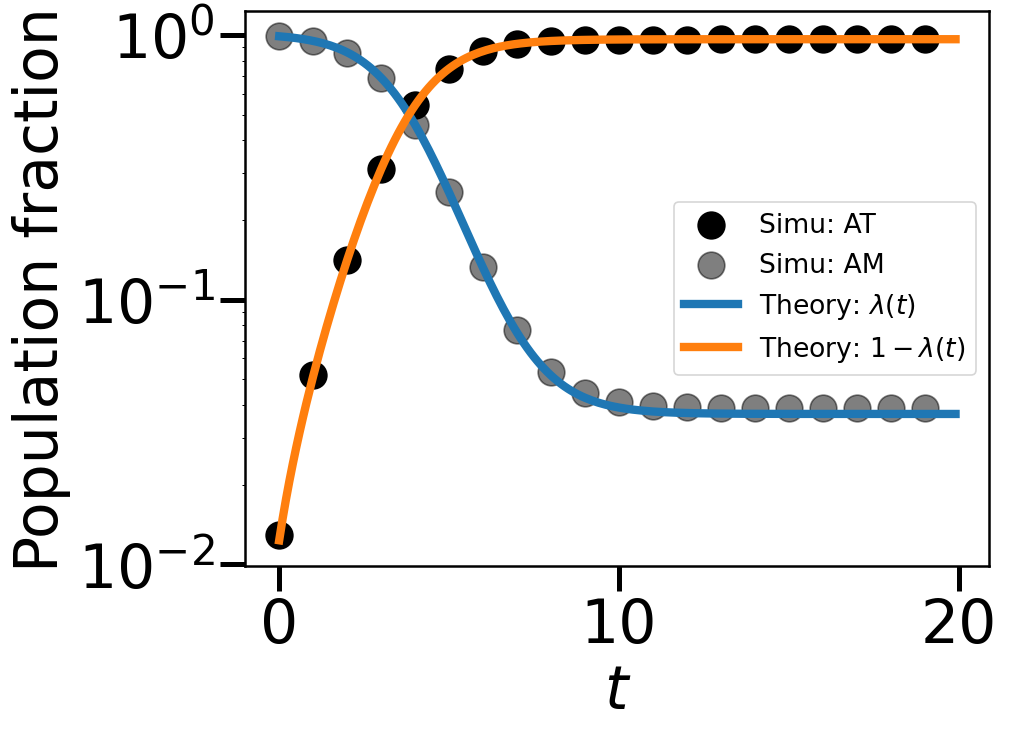

In [40]:
t=np.arange(len(fAT))*dt

plt.scatter(t[::10],fAT[::10],color='k',label='Simu: AT')
plt.scatter(t[::10],fAM[::10],color='k',alpha=0.5,label='Simu: AM')

plt.plot(t,1-lambda_t,label='Theory: '+r'$\lambda(t)$')
plt.plot(t,lambda_t,label='Theory: '+r'$1-\lambda(t)$')
plt.xlabel(r'$t$')
plt.ylabel('Population fraction')
plt.legend()
plt.semilogy()
plt.savefig('A_pop.svg')

# Fig S10

In [84]:
tau=20
nu=5*10**(-2)
mu=10**(-5)
Q=4
dt=0.01
Pops=compete_four_pops_multinomial(tau, mu, nu, dt, PopSize=10**12, steps=int(10*tau/dt))
lambda_t=compute_lambda(dt,nu,tau,Q)
f0_NM, f0_NT, f0_TT, f0_TM=compute_the_CI(lambda_t,dt,mu,nu,Q)

f_NM, f_NT, f_TT, f_TM=compute_fractions_whole(lambda_t,
    dt, mu, nu, Q, f0_NM, f0_NT, f0_TT, f0_TM)

t=np.arange(len(f_NM))*dt
Pops=Pops[:len(t),:,:]

[]

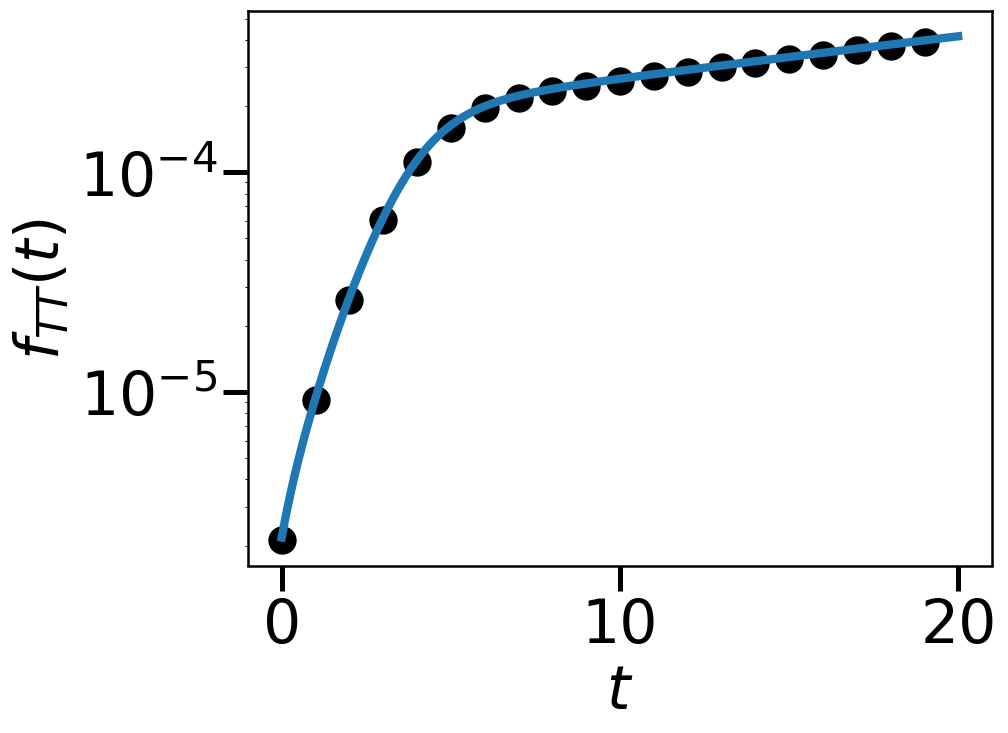

In [90]:
plt.plot(t,f_TT,label='Theory')
plt.scatter(t[::100],Pops[::100,1,1],color='k',label='Simu')
plt.xlabel(r'$t$')
plt.ylabel(r'$f_{TT}(t)$')
plt.semilogy()
#plt.savefig('f_TT.svg')

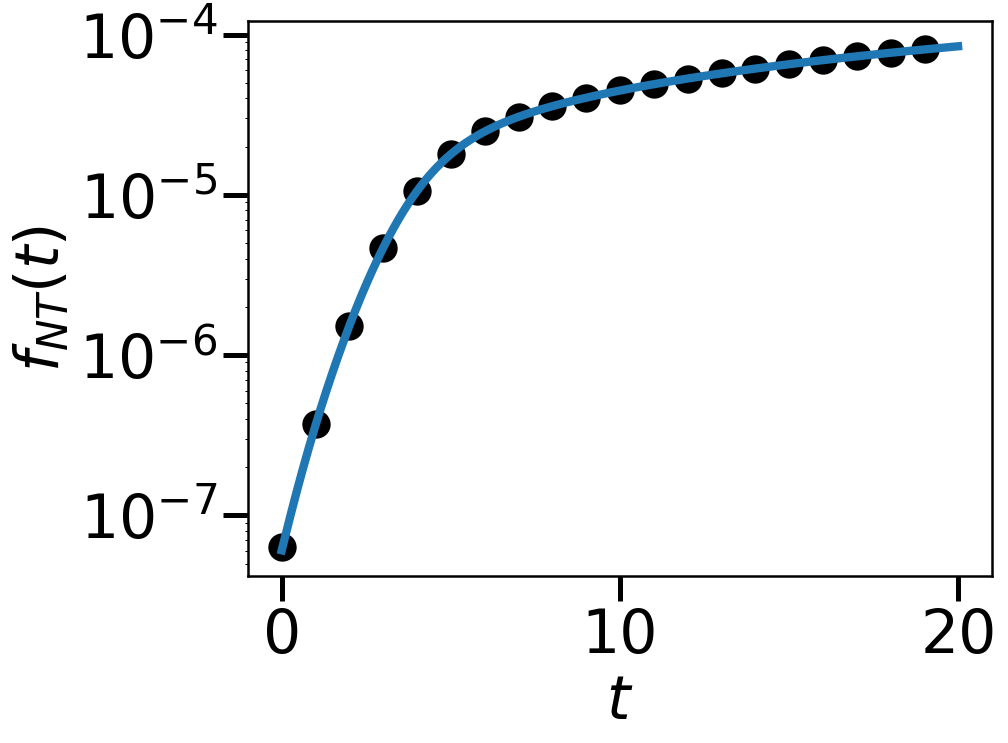

In [91]:
plt.plot(t,f_NT,label='Theory')
plt.scatter(t[::100],np.sum(Pops[:int(tau/dt):100,2:,1],axis=1),color='k',label='Simu')
plt.xlabel(r'$t$')
plt.ylabel(r'$f_{NT}(t)$')
plt.semilogy()
plt.savefig('f_NT.svg')

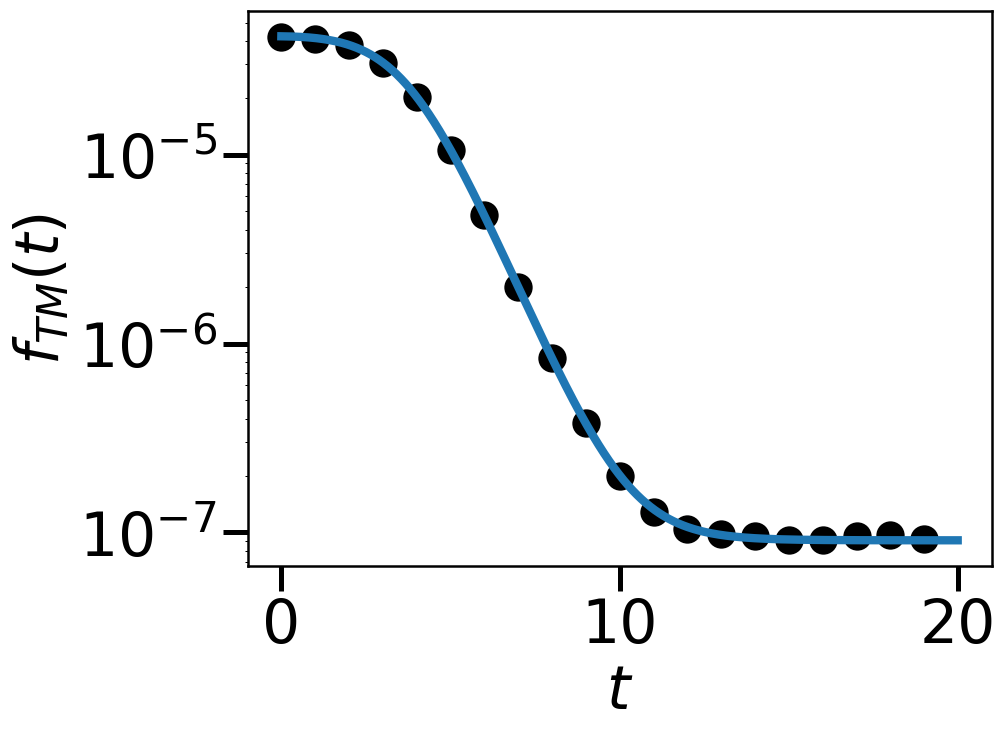

In [92]:
plt.plot(t,f_TM,label='Theory')
plt.scatter(t[::100],np.sum(Pops[:int(tau/dt):100,1,2:],axis=1)+Pops[:int(tau/dt):100,1,0],color='k',label='Simu')
plt.xlabel(r'$t$')
plt.ylabel(r'$f_{TM}(t)$')
plt.semilogy()
plt.savefig('f_TM.svg')

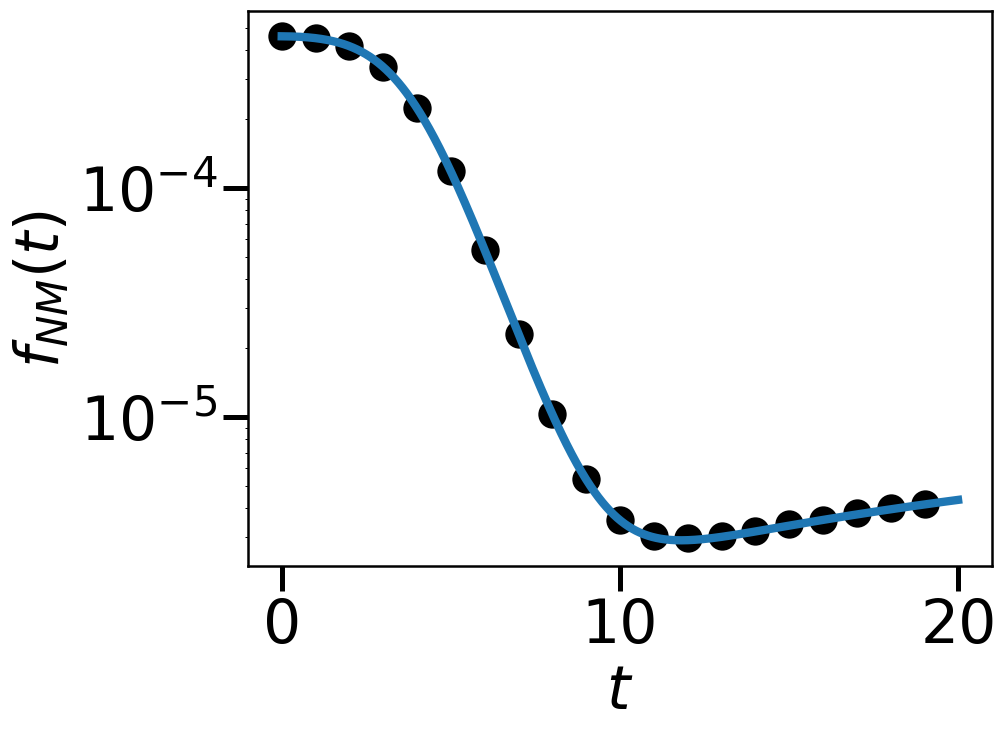

In [93]:
plt.plot(t,f_NM,label='Theory')
plt.scatter(t[::100],np.sum(np.sum(Pops[:int(tau/dt):100,2:,2:],axis=1),axis=1)+np.sum(Pops[:int(tau/dt):100,2:,0],axis=1),color='k',label='Simu')
plt.xlabel(r'$t$')
plt.ylabel(r'$f_{NM}(t)$')
plt.semilogy()
plt.savefig('f_NM.svg')

# Fig S11

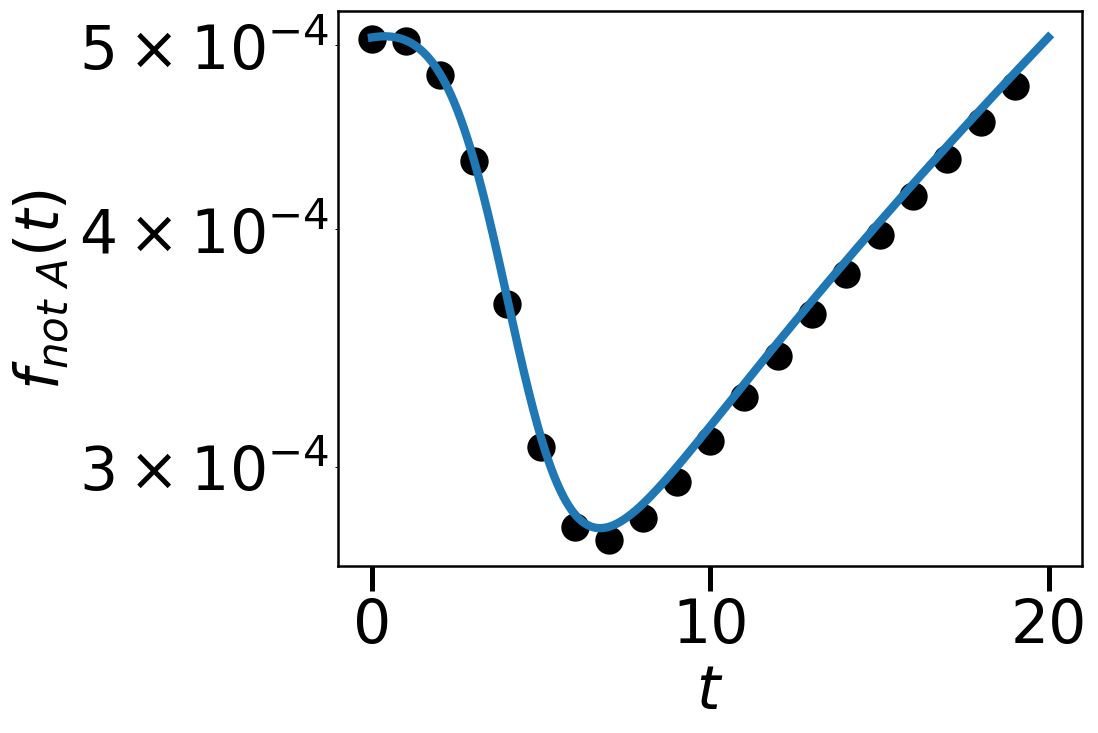

In [94]:
plt.plot(t,f_NM+f_TT+f_NT+f_TM,label='Theory')
plt.scatter(t[::100],1-np.sum(Pops[:int(tau/dt):100,0,:],axis=1),color='k',label='Simu')
plt.xlabel(r'$t$')
plt.ylabel(r'$f_{not~A}(t)$')
plt.semilogy()
plt.savefig('f_not_A.svg')

# Fig S12

In [104]:
def compute_nonA_fraction(tau,dt,mu, nu,Q):
    lamb=compute_lambda(dt,nu,tau,Q)
    [f0_NM, f0_NT, f0_TT, f0_TM]=compute_the_CI(lamb,dt,mu,nu,Q)
    [f_NM, f_NT, f_TT, f_TM]=compute_fractions_whole(lamb,dt, mu, nu, Q,f0_NM, f0_NT, f0_TT, f0_TM)
    return np.mean(f_NM+f_NT+f_TT+f_TM)

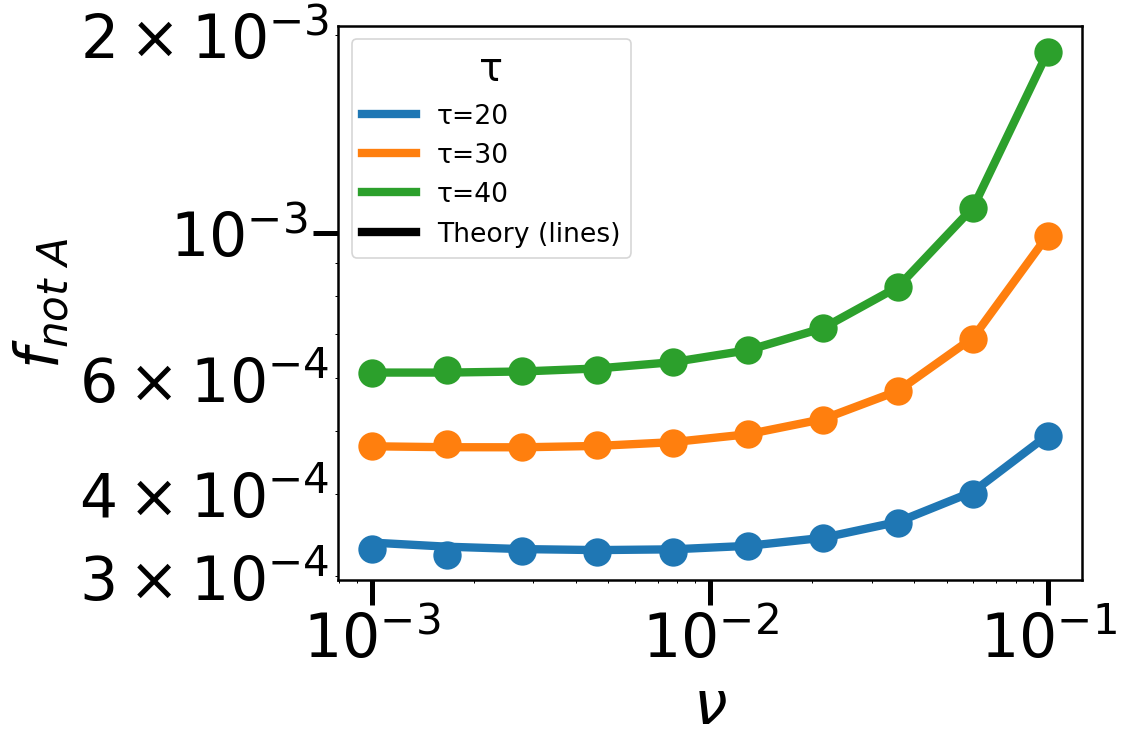

In [107]:
for tau in [20, 30, 40]:
    fnon_A = []
    fnon_A_theo = []
    dt = 1e-2
    mu = 1e-5
    Q = 4
    
    nu_lis = np.logspace(-3, -1, 10)
    for nu in nu_lis:
        res = compete_four_pops_multinomial(
            tau, mu, nu, dt, PopSize=10**12, steps=int(tau/dt*10)
        )
        fnon_A.append(1 - np.mean(np.sum(res[:, 0, :], axis=1)))
        fnon_A_theo.append(compute_nonA_fraction(tau, dt, mu, nu, Q))

    # Your original line and point plotting
    plt.plot(nu_lis, fnon_A_theo, label=f'τ={tau}')
    plt.scatter(nu_lis, fnon_A)

plt.xlabel(r'$\nu$')
plt.ylabel(r'$f_{not~A}$')
plt.semilogx()
plt.semilogy()

# ---- Add theory legend entry at the bottom ----
theory_proxy = mlines.Line2D([], [], color='black', label='Theory (lines)')

# Existing handles
handles, labels = plt.gca().get_legend_handles_labels()

# Append the theory entry at the bottom
handles = handles + [theory_proxy]
labels = labels + ['Theory (lines)']

plt.legend(handles, labels, title='τ')

#plt.savefig('fnonA_exact.svg')
#plt.savefig('fnonA_exact.png')


# Fig S14

In [96]:
# =========================
# Fitness
# =========================

@njit(parallel=True)
def energy_all(VR, H):
    N, L = VR.shape
    fit = np.zeros(N)
    for i in prange(N):
        s = 0.0
        for j in range(L):
            s += H[j, VR[i, j]]
        fit[i] = s
    return fit


# =========================
# Reproduction (JIT)
# =========================

@njit
def reproduce(VR, TR, Fitness, dt):
    PopSize, x = VR.shape

    weights = np.empty(PopSize)
    total = 0.0
    for i in range(PopSize):
        w = np.exp(dt * Fitness[i])
        weights[i] = w
        total += w

    cdf = np.empty(PopSize)
    s = 0.0
    for i in range(PopSize):
        s += weights[i] / total
        cdf[i] = s

    new_VR = np.empty_like(VR)
    new_TR = np.empty_like(TR)
    new_F = np.empty_like(Fitness)

    for i in range(PopSize):
        r = np.random.random()
        j = np.searchsorted(cdf, r)
        new_VR[i] = VR[j]
        new_TR[i] = TR[j]
        new_F[i] = Fitness[j]

    return new_VR, new_TR, new_F


# =========================
# DGR mutation
# =========================

@njit
def mutate_dgr(VR, TR, Q):
    n_ind, x = VR.shape
    new_VR = VR.copy()
    for i in range(n_ind):
        for j in range(x):
            if TR[i, j] == 0:
                new_VR[i, j] = np.random.randint(Q)
            else:
                new_VR[i, j] = TR[i, j]
    return new_VR


# =========================
# Point mutation
# =========================

@njit(parallel=True)
def apply_point_mutation(TR, mu_dt, Q):
    PopSize, x = TR.shape
    for i in prange(PopSize):
        for j in range(x):
            if np.random.random() < mu_dt:
                TR[i, j] = np.random.randint(Q)
    return TR


# =========================
# Statistics
# =========================

@njit
def compute_stats(TR, x):
    PopSize = TR.shape[0]
    fT = np.zeros(x + 1)
    fN = 0.0

    for i in range(PopSize):
        cA = 0
        cT = 0
        for j in range(x):
            if TR[i, j] == 0:
                cA += 1
            elif TR[i, j] == 1:
                cT += 1
        if cA + cT < x:
            fN += 1
        fT[cT] += 1

    fT /= PopSize
    fN /= PopSize
    return fN, fT


# =========================
# FULL SIMULATION (JIT)
# =========================

@njit
def simulate_core(x, Q, dt, PopSize, mu, nu, steps):
    H = np.zeros((x, Q))
    for k in range(x):
        H[k, 1] = 1.0

    TR = np.zeros((PopSize, x), dtype=np.int8)
    VR = np.zeros((PopSize, x), dtype=np.int8)

    for p in range(PopSize):
        for k in range(x):
            VR[p, k] = 1

    Fitness = energy_all(VR, H)

    fT = np.zeros((steps, x + 1))
    fN = np.zeros(steps)

    for k in range(steps):

        # Reproduction
        VR, TR, Fitness = reproduce(VR, TR, Fitness, dt)

        # DGR mutation
        for i in range(PopSize):
            if np.random.random() < nu * dt:
                VR[i:i+1] = mutate_dgr(VR[i:i+1], TR[i:i+1], Q)

        # Point mutation
        TR = apply_point_mutation(TR, mu * dt, Q)

        # Fitness
        Fitness = energy_all(VR, H)

        # Statistics
        fN[k], fT[k] = compute_stats(TR, x)

    return fN, fT


# =========================
# Python wrapper
# =========================

def simulate(x, Q, dt, PopSize, mu, nu, steps=10000):
    # warmup compile
    simulate_core(x, Q, dt, PopSize, mu, nu, 1)

    fN, fT = simulate_core(x, Q, dt, PopSize, mu, nu, steps)
    return fN, fT


def Amat(L,mu,nu,Q): # The matrix of rates
    A=np.zeros((L+2,L+2))
    for k in range(0,L+1):
        A[k,k]=-nu/Q**L+nu/Q**(L-k)
        if k>=1:
            A[k,k-1]=mu/Q*(L-k+1)
        if k<L:
            A[k,k+1]=mu/Q*(k+1)
        A[L+1,k]=mu*L*(Q-2)/Q
    A[L+1,L+1]=mu*L*(Q-1)/Q-nu/Q**L
    return A

L = 2  # example value
f0 = np.zeros(L+2)
f0[0] = 1  # everything starts at state 0

# Parameters
mu = 1e-3
nu = 1e-1
Q = 4

# Rate matrix
A = Amat(L, mu, nu, Q)

# Time points
t_eval = np.linspace(0, 200, 800)
dt=t_eval[-1]-t_eval[-2]

# Store solution
f_t = np.zeros((L+2, len(t_eval)))
f_t[:,0]=f0
eA=expm(A * dt)
for i in range(1,len(t_eval)):
    f_t[:, i] = eA @ f_t[:,i-1]  # exact solution at time t
    f_t[:, i]=f_t[:, i]/np.sum(f_t[:,i])

In [100]:
fN,fT=simulate(L, Q, dt,  4*10**5, mu, nu, steps=int(max(t_eval/dt)))

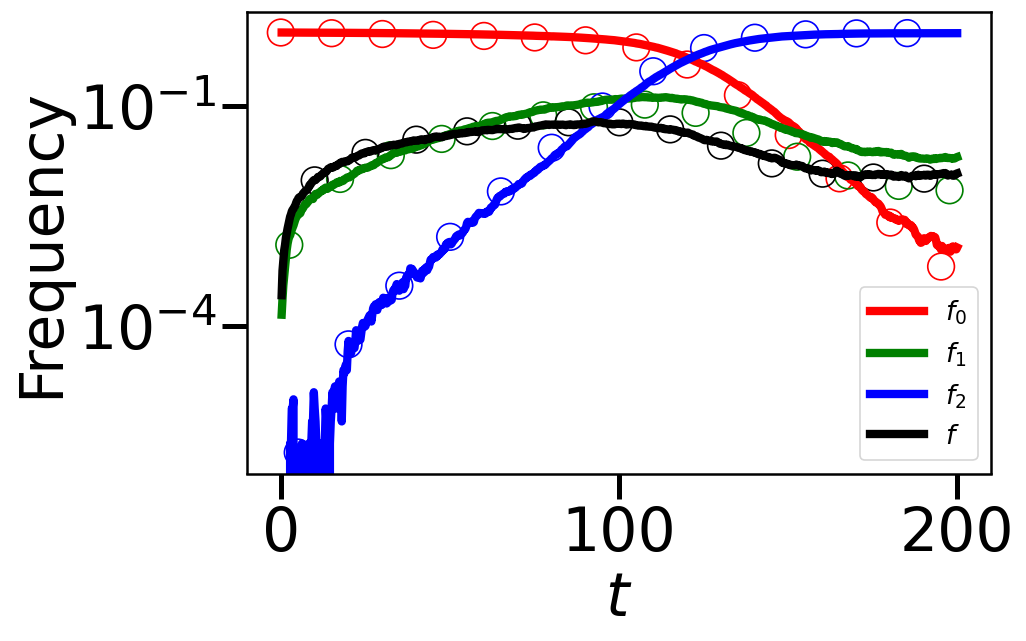

In [101]:
# Example: fT (simulated), fN (simulated), f_t (theoretical), t_eval (time)
# fT.shape = (steps, 3), fN.shape = (steps,), f_t.shape = (3, steps)

fig, ax = plt.subplots(figsize=(8,5))

colors = ['r', 'g', 'b']  # one color per type y

# --- Simulated population dynamics (solid lines) ---
for y in range(3):
    ax.plot(t_eval[1:], fT[:, y], color=colors[y], label=rf'$f_{y}$')

ax.plot(t_eval[1:], fN[:], 'k', label=r'$f$')  # total population line

# --- Theoretical frequencies (scatter points, hollow) ---
for y in range(3):
    ax.scatter(
        t_eval[y*10::60],          # select time points
        f_t[y, y*10::60],          # theoretical values
        color=colors[y],           # match simulated line
        facecolors='none',         # hollow marker
        marker='o',                # circle marker
        label='_nolegend_'         # exclude from legend
    )

# Theoretical total frequency (optional, hollow black x)
ax.scatter(
    t_eval[40::60], f_t[-1, 40::60],
    color='k', facecolors='none', label='_nolegend_'
)

# --- Plot formatting ---
ax.set_yscale('log')              # semilogy scale
ax.set_xlabel(r'$t$')
ax.set_ylabel('Frequency')
ax.legend()
#plt.savefig("Check_PDE.svg")
#plt.savefig("Check_PDE.png")
plt.show()
